# Lab 6 - Odometry localization

odometry of the `57` trajectory

In [19]:
# from google.colab import files // running locally in jupyter lab, uncomment if using colab
import numpy as np
import matplotlib.pyplot as plt

# uploaded = files.upload()

In [76]:
x_s, y_s, t_s = np.loadtxt('log/sim_odom_data_240057.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('log/real_odom_data_240057.txt', delimiter=',', unpack=True)

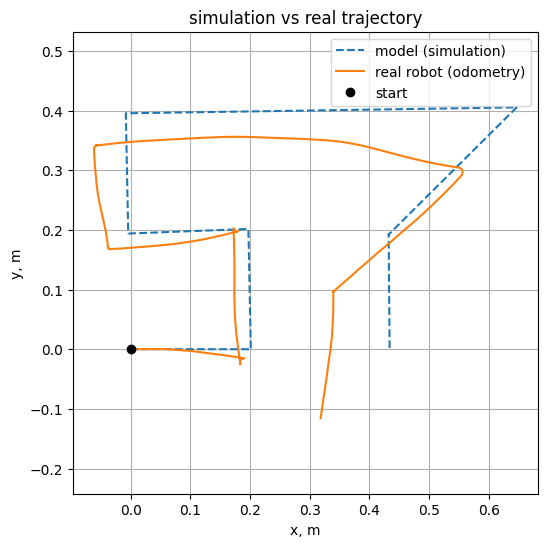

In [80]:
plt.figure(figsize=(6, 6))
plt.plot(x_s,-y_s,'--',label='model (simulation)')
plt.plot(x_r,-y_r,label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('simulation vs real trajectory')
plt.show()

## position error over time

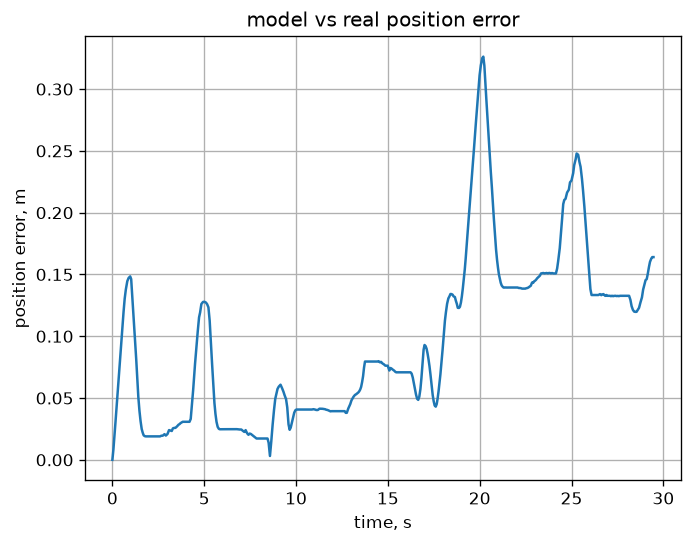

final odometry error (sim vs real): 0.164m
max error: 0.326m


In [ ]:
elapsed_s, elapsed_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(elapsed_r, elapsed_s, x_s)
ys_i = np.interp(elapsed_r, elapsed_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.figure()
plt.plot(elapsed_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('model vs real position error')
plt.show()

print(f'final odometry error (sim vs real): {err[-1]:.3f}m')
print(f'max error: {err.max():.3f}m')


## measured end point

after the real run, measure the robot's actual final position with a tape and compare it to the last line of `log/real_odom_data_240057.txt`.

In [81]:
# x_measured, y_measured = #TBM,TBM
x_measured, y_measured = x_s[-1], y_s[-1] # !TMP until i get to run odom on real robot // UPD: not necessary

print(f'odometry end point: ({x_r[-1]:.3f}, {y_r[-1]:.3f}) m')
print(f'measured end point: ({x_measured:.3f}, {y_measured:.3f}) m')
print(f'odometry vs measured: {np.hypot(x_r[-1]-x_measured, y_r[-1]-y_measured):.3f}m')

odometry end point: (0.318, 0.116) m
measured end point: (0.434, -0.001) m
odometry vs measured: 0.164m


## discussion

The real trajectory is larger than the simulated one given the fact that real robot has larger whhels, thus most of the final sim vs real error could be a scale problem rather than a drift. The divergence in shape of the numbers is mainly caused by unequal motors of real robot. 
The robot does not know its true position is wrong: it estimates movement from encoder counts and has no external position reference to detect or correct accumulated error.